Glivenko-Cantelli theorem

In this script we verify the Glivenko-Cantelli theorem.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import lognorm, kstest

In [8]:
# ---------------------------------------------------------------------------
# 2. Historical cdf (eq. 17.24) and true cdf
# Pass no weights and we get the historical dcf
# Pass flexible probabilities and het the HFP cdf
# ---------------------------------------------------------------------------
def hfp_cdf(x_grid, scenarios, p=None):
    """HFP cdf  F(x) = sum_t p_t * 1{eps_t <= x}  (eq. 17.29).
    With p=None the weights are 1/t_bar, i.e. the historical cdf (eq. 17.24)."""
    t = len(scenarios)
    p = np.full(t, 1.0 / t) if p is None else np.asarray(p)
    order = np.argsort(scenarios)
    cum_p = np.concatenate(([0.0], np.cumsum(p[order])))   # staircase heights
    idx = np.searchsorted(scenarios[order], x_grid, side="right")
    return cum_p[idx]

1. Generate lognormal scenarios

In [9]:
# location of ln(eps)
mu = 0.0
# variance of ln(eps) -> ARPM's LogN(0, 0.25)
sigma2 = 0.25
# number of observation
t_bar = 2500
# giving seed of 42 so reproducible
rng = np.random.default_rng(42)

# true distribution F_eps
dist = lognorm(s=np.sqrt(sigma2), scale=np.exp(mu))
#
eps = dist.rvs(size=t_bar, random_state=rng)

2. Compute historical and true lognormal cdf

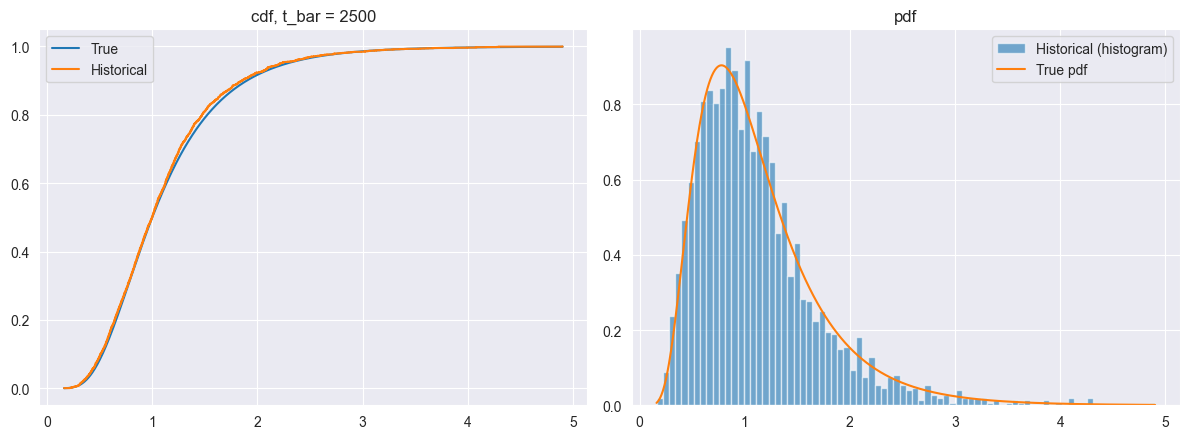

In [10]:
# True pdf vs normalised histogram (the historical pdf, "smoothed" into bins)

#
x_grid = np.linspace(eps.min(), eps.max(), 1000)
#
cdf_hist = hfp_cdf(x_grid, eps)
#
cdf_true = dist.cdf(x_grid)
#
pdf_true = dist.pdf(x_grid)

#
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(x_grid, cdf_true, label="True")
ax[0].step(x_grid, cdf_hist, where="post", label="Historical")
ax[0].set_title(f"cdf, t_bar = {t_bar}")
ax[0].legend()

ax[1].hist(eps, bins=80, density=True, alpha=0.6, label="Historical (histogram)")
ax[1].plot(x_grid, pdf_true, label="True pdf")
ax[1].set_title("pdf")
ax[1].legend()
fig.tight_layout()

4. Extra: Watch the theorem happen (sup distance shrinks as t_bar grows)

   t_bar |   sup|F_hist - F | 1/sqrt(t_bar)
      50 |           0.1752 |        0.1414
     200 |           0.0515 |        0.0707
    1000 |           0.0250 |        0.0316
    5000 |           0.0116 |        0.0141
   20000 |           0.0077 |        0.0071
  100000 |           0.0057 |        0.0032


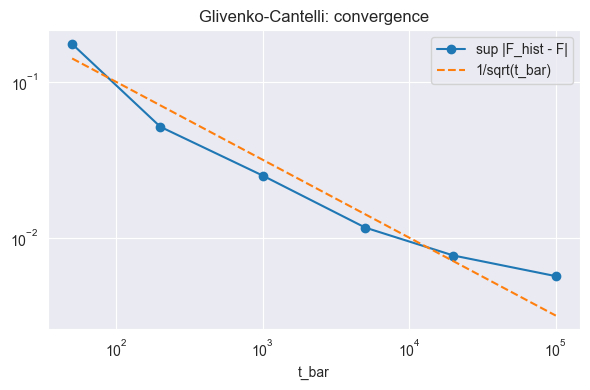

In [11]:
# kstest's statistic is exactly sup_x | F_hist(x) - F(x)|
# (eq. 17.26)
t_bars = np.array([50, 200, 1_000, 5_000, 20_000, 100_000])
sup_dist= np.array([
    kstest(dist.rvs(size=t, random_state=rng), dist.cdf).statistic
    for t in t_bars
])

print(f"{'t_bar':>8} | {'sup|F_hist - F':>16} | {'1/sqrt(t_bar)':>13}")
for t, d in zip(t_bars, sup_dist):
    print(f"{t:>8} | {d:>16.4f} | {1/np.sqrt(t):>13.4f}")

fig2, ax2 = plt.subplots(figsize=(6, 4))
ax2.loglog(t_bars, sup_dist, "o-", label="sup |F_hist - F|")
ax2.loglog(t_bars, 1 / np.sqrt(t_bars), "--", label="1/sqrt(t_bar)")
ax2.set_xlabel("t_bar")
ax2.set_title("Glivenko-Cantelli: convergence")
ax2.legend()
fig2.tight_layout()

# Pycharm needs this to open plot windows
plt.show()